# Welcome to Modal notebooks!

Write Python code and collaborate in real time. Your code runs in Modal's
**serverless cloud**, and anyone in the same workspace can join.

This notebook comes with some common Python libraries installed. Run
cells with `Shift+Enter`.

100%|█████████████████████████████████████████████████████████████████████| 1.26G/1.26G [00:15<00:00, 85.7MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3
Files available: ['accepted_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018q4.csv', 'rejected_2007_to_2018Q4.csv.gz', 'rejected_2007_to_2018q4.csv']
Loaded 2,260,701 rows, 151 columns
Train: 826,602 | Test: 518,334
  [Train] step=50,000 | profit=$12,244,126 | NPL=11.92%
  [Train] step=100,000 | profit=$29,824,866 | NPL=11.42%
  [Train] step=150,000 | profit=$47,160,854 | NPL=11.27%
  [Train] step=200,000 | profit=$62,569,187 | NPL=11.26%
  [Train] step=250,000 | profit=$78,862,871 | NPL=11.24%
  [Train] step=300,000 | profit=$90,414,841 | NPL=11.38%
  [Train] step=350,000 | profit=$104,594,136 | NPL=11.41%
  [Train] step=400,000 | profit=$120,763,058 | NPL=11.37%
  [Train] step=450,000 | profit=$135,680,515 | NPL=11.35%
  [Train] step=500,000 | profit=$152,690,314 | NPL=11.28%
  [Train] step=550,000 | profit=$168,554,461 | NPL=11.24%
  [Train] step=600,000 | profit=$188,588,520 | NPL=11.15%
  [Train] 

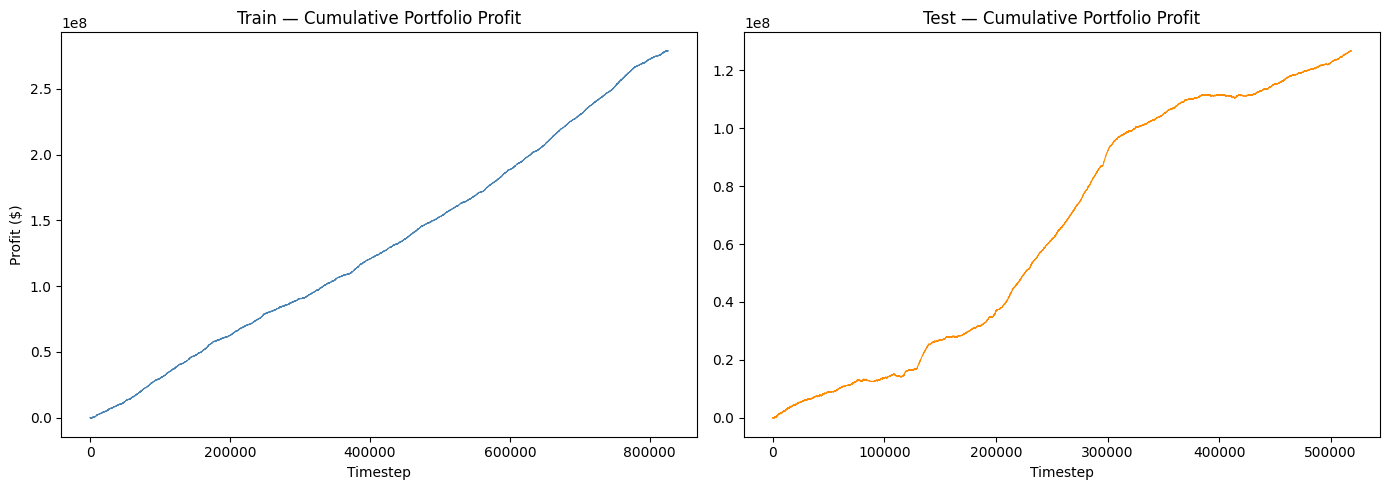


Summary:
  Train | profit=$278,835,359 | NPL=10.93%
  Test  | profit=$126,661,332  | NPL=12.35%


In [6]:
import kagglehub
import pandas as pd
import os
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import NotFittedError
import matplotlib.pyplot as plt


# 1. LOAD DATA
print("Downloading LendingClub data from Kaggle...")
path = kagglehub.dataset_download("wordsforthewise/lending-club")
print(f"Downloaded to: {path}")
print("Files available:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "accepted_2007_to_2018q4.csv", "accepted_2007_to_2018Q4.csv"), low_memory=False)
print(f"Loaded {len(df):,} rows, {df.shape[1]} columns")


# 2. PREPROCESS
# Keep only known outcomes
df = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
df["default"] = (df["loan_status"] == "Charged Off").astype(int)

# Pull raw columns needed for feature engineering + meta columns
raw_cols = ["fico_range_low", "dti", "annual_inc", "grade", "int_rate",
            "loan_amnt", "installment", "issue_d"]
df = df[raw_cols + ["default"]].copy()

# --- Feature Engineering ---

# grade → ordinal int (A=0, B=1, ..., G=6)
grade_map = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6}
df["grade"] = df["grade"].map(grade_map)

# total_interest_burden: estimated total interest paid over loan life
# approximated as int_rate (%) * loan_amnt
df["total_interest_burden"] = (df["int_rate"] / 100) * df["loan_amnt"]

# payment_to_income: monthly installment as fraction of monthly income
df["annual_inc"] = df["annual_inc"].clip(lower=1)          # avoid div/0
df["payment_to_income"] = df["installment"] / (df["annual_inc"] / 12)

# Log-transform skewed numerics
df["dti"]                   = np.log1p(df["dti"].clip(lower=0))
df["total_interest_burden"] = np.log1p(df["total_interest_burden"].clip(lower=0))
df["payment_to_income"]     = np.log1p(df["payment_to_income"].clip(lower=0))

# Drop nulls
df = df.dropna()

# Feature list used by the agent
features = ["total_interest_burden", "grade", "fico_range_low", "payment_to_income", "dti"]

# Temporal train/test split
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
train_df = df[df["issue_d"] < "2016-01-01"].copy().reset_index(drop=True)
test_df  = df[df["issue_d"] >= "2016-01-01"].copy().reset_index(drop=True)

print(f"Train: {len(train_df):,} | Test: {len(test_df):,}")


# 3. ENVIRONMENT
class LendingEnv:
    RATE_TIERS = {1: 0.08, 2: 0.13, 3: 0.19}

    def __init__(self, df, feature_cols):
        self.df   = df.reset_index(drop=True)
        self.cols = feature_cols
        self.idx  = 0

    def reset(self):
        self.idx = 0
        return self._obs()

    def _obs(self):
        row = self.df.iloc[self.idx]
        return row[self.cols].values.astype(float), row

    def step(self, action):
        _, row    = self._obs()
        defaulted = int(row["default"])
        loan_amnt = float(row["loan_amnt"])

        if action == 0:
            reward = 0.0
        elif defaulted:
            reward = -loan_amnt
        else:
            reward = self.RATE_TIERS[action] * loan_amnt

        self.idx   += 1
        done        = self.idx >= len(self.df)
        next_obs    = None if done else self._obs()
        return next_obs, reward, done, {"default": defaulted, "action": action}


# 4. BANDIT AGENT
class GreedyContextualBandit:
    def __init__(self, n_features, epsilon=0.1):
        self.epsilon = epsilon
        self.scalers = {a: StandardScaler() for a in [1, 2, 3]}
        self.models  = {
            a: LogisticRegression(max_iter=1000, warm_start=True)
            for a in [1, 2, 3]
        }
        self.buffers = {a: ([], []) for a in [1, 2, 3]}
        self.trained = {a: False for a in [1, 2, 3]}

    def _expected_reward(self, features, action, loan_amnt):
        rate = LendingEnv.RATE_TIERS[action]
        if not self.trained[action]:
            return rate * loan_amnt * 0.85
        X       = self.scalers[action].transform([features])
        p_repay = self.models[action].predict_proba(X)[0][0]
        return p_repay * rate * loan_amnt - (1 - p_repay) * loan_amnt

    def select_action(self, features, loan_amnt):
        if np.random.rand() < self.epsilon:
            return np.random.choice([0, 1, 2, 3])
        expected = {0: 0.0}
        expected.update({a: self._expected_reward(features, a, loan_amnt) for a in [1, 2, 3]})
        return max(expected, key=expected.get)

    def update(self, action, features, outcome, min_samples=50, retrain_every=200):
        if action == 0:
            return
        X_buf, y_buf = self.buffers[action]
        X_buf.append(features)
        y_buf.append(outcome)
        n = len(X_buf)
        if n >= min_samples and n % retrain_every == 0:
            X = np.array(X_buf)
            y = np.array(y_buf)
            if len(np.unique(y)) < 2:
                return
            self.scalers[action].fit(X)
            self.models[action].fit(self.scalers[action].transform(X), y)
            self.trained[action] = True


# 5. SIMULATION LOOP
def run_simulation(env, agent, split_name="Train"):
    obs_tuple = env.reset()
    total_profit, n_approved, n_defaults, step = 0.0, 0, 0, 0
    profit_curve = []

    while True:
        features, row = obs_tuple
        loan_amnt     = float(row["loan_amnt"])
        action        = agent.select_action(features, loan_amnt)
        next_obs, reward, done, info = env.step(action)

        total_profit += reward
        if action != 0:
            n_approved += 1
            if info["default"]:
                n_defaults += 1
            agent.update(action, features, info["default"])

        step += 1
        profit_curve.append(total_profit)

        if step % 50_000 == 0:
            npl = n_defaults / max(n_approved, 1)
            print(f"  [{split_name}] step={step:,} | profit=${total_profit:,.0f} | NPL={npl:.2%}")

        if done:
            break
        obs_tuple = next_obs

    npl = n_defaults / max(n_approved, 1)
    print(f"\n{'='*55}")
    print(f"[{split_name}] FINAL RESULTS")
    print(f"  Total profit   : ${total_profit:,.0f}")
    print(f"  Approved loans : {n_approved:,}")
    print(f"  NPL ratio      : {npl:.2%}  (target < 5%)")
    print(f"  Avg profit/loan: ${total_profit / max(n_approved, 1):,.2f}")
    print(f"{'='*55}\n")
    return profit_curve, {"profit": total_profit, "npl": npl, "approved": n_approved}


# 6. RUN TRAIN
train_env = LendingEnv(train_df, features)
agent     = GreedyContextualBandit(n_features=len(features), epsilon=0.1)
train_curve, train_metrics = run_simulation(train_env, agent, split_name="Train")

# 7. RUN TEST (greedy only, no exploration)
agent.epsilon = 0.0
test_env      = LendingEnv(test_df, features)
test_curve, test_metrics = run_simulation(test_env, agent, split_name="Test")


# 8. PLOT
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_curve, color="steelblue", linewidth=0.8)
axes[0].set_title("Train — Cumulative Portfolio Profit")
axes[0].set_xlabel("Timestep")
axes[0].set_ylabel("Profit ($)")

axes[1].plot(test_curve, color="darkorange", linewidth=0.8)
axes[1].set_title("Test — Cumulative Portfolio Profit")
axes[1].set_xlabel("Timestep")

plt.tight_layout()
plt.show()

print(f"\nSummary:")
print(f"  Train | profit=${train_metrics['profit']:,.0f} | NPL={train_metrics['npl']:.2%}")
print(f"  Test  | profit=${test_metrics['profit']:,.0f}  | NPL={test_metrics['npl']:.2%}")